# Titanic

In this task I look at the passengers of the Titanic and try to see who survived more.

Columns I will use:

| Column | Meaning |
|---|---|
| survived | 1 = yes, 0 = no |
| pclass | class of the ticket (1, 2, 3) |
| sex | male or female |
| age | age of the passenger |
| fare | price of the ticket |

## Libraries

- pandas: tables and csv files
- numpy: arrays
- matplotlib: plots
- seaborn: only to download the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the data

First I download the data, save it as csv, and read it again with pandas.

In [2]:
sns.load_dataset("titanic").to_csv("titanic.csv", index=False)

df = pd.read_csv("titanic.csv")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## DataFrame

In [3]:
df.shape

(891, 15)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 116.9 KB


In [5]:
df.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [6]:
df.drop(columns=["deck", "alive", "embarked", "embark_town"], inplace=True)
df.dropna(subset=["age"], inplace=True)
df.isna().sum()

survived      0
pclass        0
sex           0
age           0
sibsp         0
parch         0
fare          0
class         0
who           0
adult_male    0
alone         0
dtype: int64

In [7]:
df.shape

(714, 11)

In [8]:
women = df[df["sex"] == "female"]
print(len(women))

df[df["age"] > 60].head()

261


,survived,pclass,sex,age,sibsp,parch,fare,class,who,adult_male,alone
33,0,2,male,66.0,0,0,10.5000,Second,man,True,True
54,0,1,male,65.0,0,1,61.9792,First,man,True,False
96,0,1,male,71.0,0,0,34.6542,First,man,True,True
116,0,3,male,70.5,0,0,7.7500,Third,man,True,True
170,0,1,male,61.0,0,0,33.5000,First,man,True,True


Survival rate for men and women. The mean of `survived` is the percent of people who survived.

In [9]:
men = df[df["sex"] == "male"]

print("women:", women["survived"].mean())
print("men:", men["survived"].mean())

women: 0.7547892720306514
men: 0.2052980132450331


Survival rate for each class.

In [10]:
first = df[df["pclass"] == 1]
second = df[df["pclass"] == 2]
third = df[df["pclass"] == 3]

print("first class:", first["survived"].mean())
print("second class:", second["survived"].mean())
print("third class:", third["survived"].mean())

first class: 0.6559139784946236
second class: 0.4797687861271676
third class: 0.23943661971830985


## ndarray

In [11]:
ages = df["age"].to_numpy()

print(type(ages))
print(ages.shape)
print(ages.ndim)
print(ages.mean())

<class 'numpy.ndarray'>
(714,)
1
29.69911764705882


In [12]:
children = ages[ages < 12]
print(len(children))

68


In [13]:
data = df[["age", "fare"]].to_numpy()
print(data.shape)
data[:5]

(714, 2)


array([[22.    ,  7.25  ],
       [38.    , 71.2833],
       [26.    ,  7.925 ],
       [35.    , 53.1   ],
       [35.    ,  8.05  ]])

## Numeric

In [14]:
df[["age", "fare"]].describe()

,age,fare
count,714.000000,714.000000
mean,29.699118,34.694514
std,14.526497,52.918930
min,0.420000,0.000000
25%,20.125000,8.050000
50%,28.000000,15.741700
75%,38.000000,33.375000
max,80.000000,512.329200


In [15]:
age = df["age"]

print("mean:", age.mean())
print("median:", age.median())
print("variance:", age.var())
print("std:", age.std())
print("skew:", age.skew())
print("kurtosis:", age.kurt())

mean: 29.69911764705882
median: 28.0
variance: 211.01912474630805
std: 14.526497332334042
skew: 0.38910778230082693
kurtosis: 0.1782741536421022


In [16]:
df[["survived", "pclass", "age", "fare"]].corr()

,survived,pclass,age,fare
survived,1.000000,-0.359653,-0.077221,0.268189
pclass,-0.359653,1.000000,-0.369226,-0.554182
age,-0.077221,-0.369226,1.000000,0.096067
fare,0.268189,-0.554182,0.096067,1.000000


## Plots

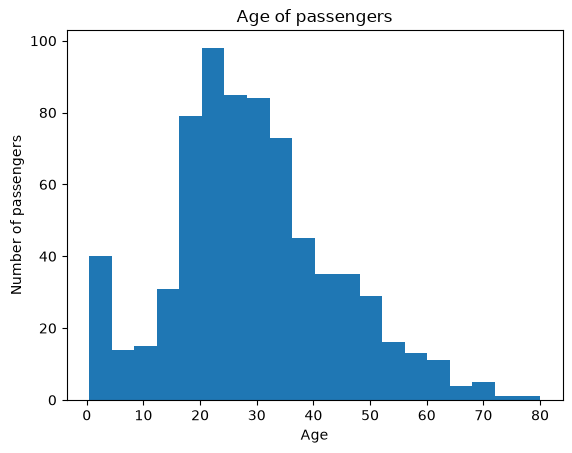

In [17]:
plt.hist(df["age"], bins=20)
plt.title("Age of passengers")
plt.xlabel("Age")
plt.ylabel("Number of passengers")
plt.show()

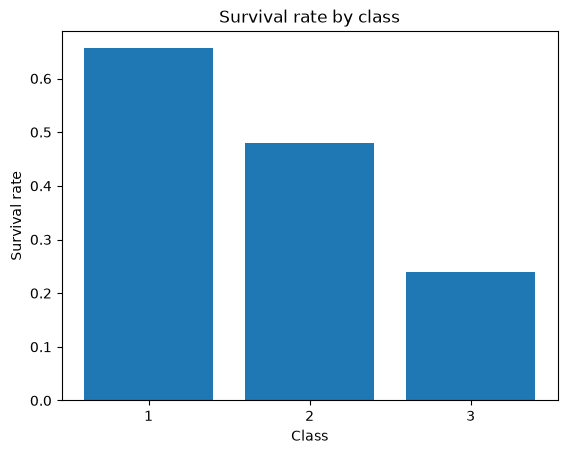

In [18]:
rates = [first["survived"].mean(), second["survived"].mean(), third["survived"].mean()]

plt.bar(["1", "2", "3"], rates)
plt.title("Survival rate by class")
plt.xlabel("Class")
plt.ylabel("Survival rate")
plt.show()

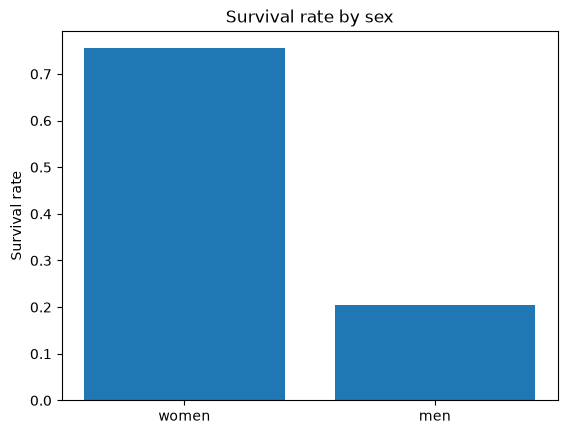

In [19]:
plt.bar(["women", "men"], [women["survived"].mean(), men["survived"].mean()])
plt.title("Survival rate by sex")
plt.ylabel("Survival rate")
plt.show()

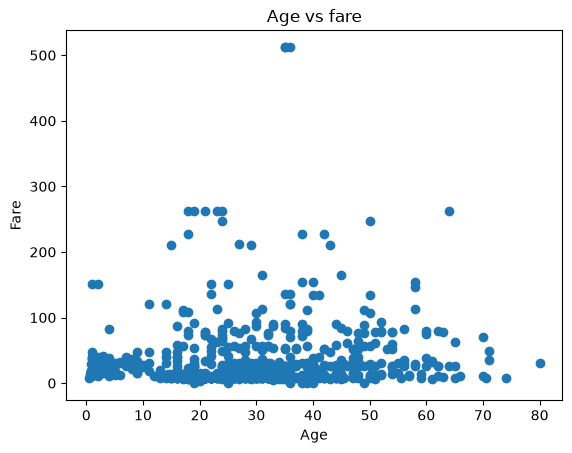

In [20]:
plt.scatter(df["age"], df["fare"])
plt.title("Age vs fare")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.show()

## Conclusion

- Women survived more than men.
- First class passengers survived more than third class.
- A few passengers paid a very high fare.